# Week 5 — Floor 6 contextual baseline + MAD

This notebook applies the Week 5 statistical anomaly workflow to the established Week 4 scope: **Floor 6, Zones 1/2/4/5, 2018-07-01 00:00 through 2018-09-01 23:59**.

The input remains a **one-minute row-level dataset**. Detection uses the existing `total_AC_power_kw_rolling_mean_15min` feature (a rolling mean over 15 one-minute records); it is not a 15-minute-resampled dataset. The raw `total_AC_power_kw` field is retained for interpretation.

In [1]:
from pathlib import Path
from IPython.display import Image, display
import pandas as pd

from week5_floor6_contextual_mad import (
    ANALYSIS_END, ANALYSIS_START, CONTEXT_COLUMNS, FIGURE_DIR, INPUT_FILE,
    OUTPUT_DIR, RAW_TARGET_COLUMN, ROBUST_Z_THRESHOLD, TARGET_COLUMN,
    run_week5_analysis,
)

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 180)

## Scope and source-of-truth input

Week 5 consumes the cleaned/smoothed output already defined by the completed Week 4 notebook. It does not repeat AC-meter aggregation, cleaning, smoothing, or EDA.

In [2]:
scope = {
    'input_file': str(INPUT_FILE),
    'analysis_period': f'{ANALYSIS_START} through {ANALYSIS_END}',
    'floor': 6,
    'zones': [1, 2, 4, 5],
    'raw_interpretation_field': RAW_TARGET_COLUMN,
    'smoothed_detection_target': TARGET_COLUMN,
    'context': ' + '.join(CONTEXT_COLUMNS),
    'robust_z_threshold': ROBUST_Z_THRESHOLD,
}
scope

{'input_file': 'D:\\实习任务\\Artificial-Intelligence-for-Smart-Building-Log-Analysis\\Artificial Intelligence for Smart-Building Log Analysis\\outputs\\floor6_zone1245_2018_jul01_sep01_total_ac_eda\\floor6_zone1245_cleaned_smoothed_2018_jul01_sep01.csv.gz',
 'analysis_period': '2018-07-01 00:00:00 through 2018-09-01 23:59:00',
 'floor': 6,
 'zones': [1, 2, 4, 5],
 'raw_interpretation_field': 'total_AC_power_kw',
 'smoothed_detection_target': 'total_AC_power_kw_rolling_mean_15min',
 'context': 'zone + day_type + hour',
 'robust_z_threshold': 3.5}

## Run the complete workflow

For each `zone + day_type + hour` context, the workflow calculates the mean and median, uses the median as the robust expected baseline, and evaluates residuals with contextual MAD. The normal rule is `|robust z| > 3.5`. Where contextual MAD is zero, the code avoids division by zero and uses a separately labelled empirical-resolution fallback. Missing smoothed targets remain excluded.

In [3]:
results = run_week5_analysis()

Input rows: 362,880
Valid smoothed observations: 361,621
Excluded smoothed targets: 1,259
Statistical anomalies: 19,892 (5.5008%)
Contexts: 192; MAD=0 contexts: 160
Fallback anomalies: 11,508
Estimated empirical rolling-AC resolution: 0.000666 kW (total_AC_power_kw_rolling_mean_15min)


## Scope, context support, and overall result

Hour-level contexts were retained because every selected context has at least 1,076 valid historical observations, compared with 266 for the finer 15-minute-slot alternative. This gives a stable, interpretable V1 context for roughly two months of one-minute data while the detection signal is already smoothed.

In [4]:
display(results['context_sample_size_diagnostic'])
display(results['overall_summary'].T.rename(columns={0: 'value'}))

,context_design,contexts,minimum_valid_observations,percentile_05_valid_observations,median_valid_observations,maximum_valid_observations,selected_for_v1
0,zone + day_type + hour,192,1076,1080.0,1860.0,2700,True
1,zone + day_type + 15-minute time slot,768,266,270.0,465.0,675,False


,value
input_file,floor6_zone1245_cleaned_smoothed_2018_jul01_se...
total_rows,362880
valid_smoothed_observations_analysed,361621
excluded_smoothed_target_rows,1259
total_anomalies,19892
anomaly_rate_pct,5.500787
context_grouping,zone + day_type + hour
number_of_contexts,192
mad_zero_contexts,160
mad_zero_context_observations,276181


## Mean versus median

The mean is not mathematically wrong. The median is selected as the primary baseline because it is less influenced by occasional high-power observations and skewed contextual distributions. The tables below quantify the choice using only the current Floor 6 data.

In [5]:
display(results['mean_median_summary'].T.rename(columns={0: 'value'}))
display(results['mean_median_largest_differences'].head(10))

,value
contexts,192.000000
mean_signed_difference_kw,0.073804
mean_absolute_difference_kw,0.298251
median_absolute_difference_kw,0.000000
percentile_95_absolute_difference_kw,1.905238
weighted_mean_absolute_difference_kw,0.387040
maximum_absolute_difference_kw,4.596903
contexts_mean_above_median,71.000000
contexts_mean_above_median_pct,36.979167


,zone,day_type,hour,baseline_mean,baseline_median,baseline_count,mean_median_difference,mean_median_abs_difference,residual_median,contextual_mad,mad_zero_flag
0,2,Weekday,7,4.596903,0.000000,2640,4.596903,4.596903,0.000000e+00,0.000000,True
1,4,Weekday,7,3.892406,0.000000,2642,3.892406,3.892406,0.000000e+00,0.000000,True
2,1,Weekday,11,13.986018,17.796333,2640,-3.810315,3.810315,0.000000e+00,4.992667,False
3,1,Weekday,7,3.622258,0.000000,2640,3.622258,3.622258,0.000000e+00,0.000000,True
4,2,Weekday,8,18.662299,22.157000,2640,-3.494701,3.494701,0.000000e+00,2.241000,False
5,5,Weekday,7,3.063858,0.000000,2640,3.063858,3.063858,0.000000e+00,0.000000,True
6,1,Weekday,15,16.386005,19.223333,2700,-2.837329,2.837329,0.000000e+00,0.777667,False
7,5,Weekday,8,7.157305,4.983333,2640,2.173972,2.173972,0.000000e+00,3.954667,False
8,4,Weekday,16,7.046533,5.103667,2700,1.942866,1.942866,4.440892e-16,5.103667,False
9,2,Weekday,9,14.898614,12.977667,2640,1.920947,1.920947,0.000000e+00,3.591667,False


## MAD result and diagnostics

MAD is calculated inside the same `zone + day_type + hour` context as the baseline. A large residual is therefore unusual relative to expected contextual behaviour—not merely a high AC reading. MAD=0 contexts and any fallback classifications remain visible rather than being hidden behind an arbitrary denominator.

In [6]:
display(results['contextual_mad_distribution'])
display(results['smallest_nonzero_mad_contexts'].head(10))
display(results['by_zone'])
display(results['by_day_type'])
display(results['by_hour'])

,count,zero_count,minimum,percentile_01,percentile_05,median,mean,percentile_95,percentile_99,maximum
0,192,160,0.0,0.0,0.0,0.0,0.611894,4.646267,8.39976,13.024333


,zone,day_type,hour,baseline_median,contextual_mad,baseline_count
0,2,Weekday,15,12.554667,0.307333,2700
1,1,Weekday,14,19.320667,0.398333,2700
2,1,Weekday,9,19.108000,0.494333,2640
3,2,Weekday,14,12.667000,0.501333,2700
4,1,Weekday,10,19.215333,0.587000,2640
5,1,Weekday,8,19.197000,0.671333,2640
6,1,Weekday,15,19.223333,0.777667,2700
7,5,Weekday,16,1.040000,1.040000,2700
8,5,Weekday,15,4.412000,1.557333,2700
9,5,Weekday,10,4.739333,1.649000,2640


,zone,observations,anomalies,anomaly_rate_pct
0,1,90404,6795,7.516260
1,2,90404,5647,6.246405
2,4,90409,6219,6.878740
3,5,90404,1231,1.361665


,day_type,observations,anomalies,anomaly_rate_pct
0,Weekday,257957,17167,6.654985
1,Weekend,103664,2725,2.628685


,hour,observations,anomalies,anomaly_rate_pct
0,0,15104,129,0.854078
1,1,15120,141,0.932540
2,2,15120,119,0.787037
3,3,15120,216,1.428571
4,4,15120,277,1.832011
5,5,15120,241,1.593915
6,6,15111,306,2.025015
7,7,14882,3815,25.634995
8,8,14880,1434,9.637097
9,9,14880,1266,8.508065


## Long runs and representative statistical anomalies

Runs are segmented independently inside each zone. Consecutive anomaly rows join only when their timestamps are exactly one minute apart. Stable IDs such as `Z2-R0119` make the run definition auditable. These are statistical anomalies (pseudo-labels), not verified equipment faults.

In [7]:
display(results['anomaly_run_summary'].head(10))
display(results['representative_anomalies'])
display(results['highest_scoring_anomalies'].head(10))

,zone,anomaly_run_number,anomaly_run_id,run_start,run_end,anomaly_run_length,maximum_absolute_robust_z,maximum_absolute_residual_kw
0,2,119,Z2-R0119,2018-08-04 09:33:00,2018-08-04 17:53:00,501,NaN,25.044000
1,2,190,Z2-R0190,2018-09-01 09:34:00,2018-09-01 16:59:00,446,NaN,1.804667
2,2,133,Z2-R0133,2018-08-11 11:40:00,2018-08-11 17:30:00,351,NaN,1.316000
3,1,1,Z1-R0001,2018-07-02 07:39:00,2018-07-02 10:59:00,201,10.983025,27.720667
4,1,50,Z1-R0050,2018-07-09 07:39:00,2018-07-09 10:59:00,201,10.639180,27.618000
5,1,4,Z1-R0004,2018-07-03 07:39:00,2018-07-03 10:49:00,191,10.891151,27.208667
6,1,149,Z1-R0149,2018-07-23 07:39:00,2018-07-23 10:40:00,182,10.897519,27.811333
7,1,193,Z1-R0193,2018-07-27 13:00:00,2018-07-27 15:59:00,180,32.715790,19.543333
8,1,195,Z1-R0195,2018-07-30 13:00:00,2018-07-30 15:59:00,180,32.715790,19.543333
9,1,219,Z1-R0219,2018-08-13 13:00:00,2018-08-13 15:59:00,180,32.715790,19.543333


,selection_reason,timestamp,floor,zone,day_type,hour,total_AC_power_kw,total_AC_power_kw_rolling_mean_15min,baseline_median,residual,contextual_mad,robust_z_score,absolute_robust_z_score,anomaly_run_id,anomaly_run_length,anomaly_detection_method,why_flagged
0,Highest robust MAD score,2018-07-27 14:00:00,6,1,Weekday,14,0.00,0.000000,19.320667,-19.320667,0.398333,-32.715790,32.715790,Z1-R0193,180,robust_z_contextual_mad,Smoothed AC power was 19.3207 kW below its con...
1,Largest positive contextual residual,2018-07-02 07:59:00,6,4,Weekday,7,34.32,31.020000,0.000000,31.020000,0.000000,NaN,NaN,Z4-R0006,21,mad_zero_empirical_resolution_fallback,Smoothed AC power was 31.0200 kW above its con...
2,Largest negative contextual residual,2018-07-27 08:32:00,6,2,Weekday,8,0.00,0.000000,22.157000,-22.157000,2.241000,-6.668852,6.668852,Z2-R0098,40,robust_z_contextual_mad,Smoothed AC power was 22.1570 kW below its con...
3,Representative point from a 501-minute anomaly...,2018-08-04 09:57:00,6,2,Weekend,9,24.28,25.044000,0.000000,25.044000,0.000000,NaN,NaN,Z2-R0119,501,mad_zero_empirical_resolution_fallback,Smoothed AC power was 25.0440 kW above its con...
4,Highest-ranked example in Zone 1,2018-07-23 07:58:00,6,1,Weekday,7,27.39,27.811333,0.000000,27.811333,0.000000,NaN,NaN,Z1-R0149,182,mad_zero_empirical_resolution_fallback,Smoothed AC power was 27.8113 kW above its con...
5,Highest-ranked example in Zone 2,2018-07-02 07:59:00,6,2,Weekday,7,25.85,25.429333,0.000000,25.429333,0.000000,NaN,NaN,Z2-R0001,21,mad_zero_empirical_resolution_fallback,Smoothed AC power was 25.4293 kW above its con...
6,Highest-ranked example in Zone 5,2018-08-14 07:59:00,6,5,Weekday,7,18.73,19.242667,0.000000,19.242667,0.000000,NaN,NaN,Z5-R0071,20,mad_zero_empirical_resolution_fallback,Smoothed AC power was 19.2427 kW above its con...


,timestamp,floor,zone,day_type,hour,total_AC_power_kw,total_AC_power_kw_rolling_mean_15min,baseline_median,residual,residual_median,contextual_mad,robust_z_score,absolute_robust_z_score,fallback_epsilon_kw,anomaly_detection_method,detection_rank
0,2018-07-02 07:59:00,6,4,Weekday,7,34.32,31.020000,0.0,31.020000,0.0,0.0,NaN,NaN,0.000666,mad_zero_empirical_resolution_fallback,46576.576577
1,2018-07-05 07:59:00,6,4,Weekday,7,33.87,30.730000,0.0,30.730000,0.0,0.0,NaN,NaN,0.000666,mad_zero_empirical_resolution_fallback,46141.141141
2,2018-07-09 07:59:00,6,4,Weekday,7,33.21,30.702667,0.0,30.702667,0.0,0.0,NaN,NaN,0.000666,mad_zero_empirical_resolution_fallback,46100.100100
3,2018-07-04 07:59:00,6,4,Weekday,7,33.51,30.698667,0.0,30.698667,0.0,0.0,NaN,NaN,0.000666,mad_zero_empirical_resolution_fallback,46094.094094
4,2018-07-13 07:59:00,6,4,Weekday,7,33.74,30.358667,0.0,30.358667,0.0,0.0,NaN,NaN,0.000666,mad_zero_empirical_resolution_fallback,45583.583584
5,2018-07-06 07:59:00,6,4,Weekday,7,33.75,30.186667,0.0,30.186667,0.0,0.0,NaN,NaN,0.000666,mad_zero_empirical_resolution_fallback,45325.325325
6,2018-07-25 07:59:00,6,4,Weekday,7,33.15,30.102000,0.0,30.102000,0.0,0.0,NaN,NaN,0.000666,mad_zero_empirical_resolution_fallback,45198.198198
7,2018-07-16 07:59:00,6,4,Weekday,7,33.31,30.091333,0.0,30.091333,0.0,0.0,NaN,NaN,0.000666,mad_zero_empirical_resolution_fallback,45182.182182
8,2018-07-03 07:59:00,6,4,Weekday,7,33.25,30.028667,0.0,30.028667,0.0,0.0,NaN,NaN,0.000666,mad_zero_empirical_resolution_fallback,45088.088088
9,2018-07-23 07:59:00,6,4,Weekday,7,33.85,29.997333,0.0,29.997333,0.0,0.0,NaN,NaN,0.000666,mad_zero_empirical_resolution_fallback,45041.041041


## Week 5 model-result figures

These figures explain the baseline, contextual residuals, statistical anomaly flags, zone rates, and the mean-versus-median decision. They do not repeat Week 4 EDA.

,figure_number,file_name,description
0,1,week5_01_smoothed_ac_vs_contextual_baseline.png,Smoothed AC compared with its contextual media...
1,2,week5_02_smoothed_ac_baseline_with_mad_anomali...,"Smoothed AC, baseline and MAD anomaly points"
2,3,week5_03_contextual_residual_over_time.png,Residuals for the same high-scoring anomaly wi...
3,4,week5_04_mad_anomaly_rate_by_zone.png,"Statistical anomaly rates for Zones 1, 2, 4 and 5"
4,5,week5_05_mean_vs_median_contextual_baseline.png,Mean and median comparison across 192 Floor 6 ...
5,6,week5_06_mad_explanation_case_study.png,Two-panel explanation of the Floor 6 contextua...


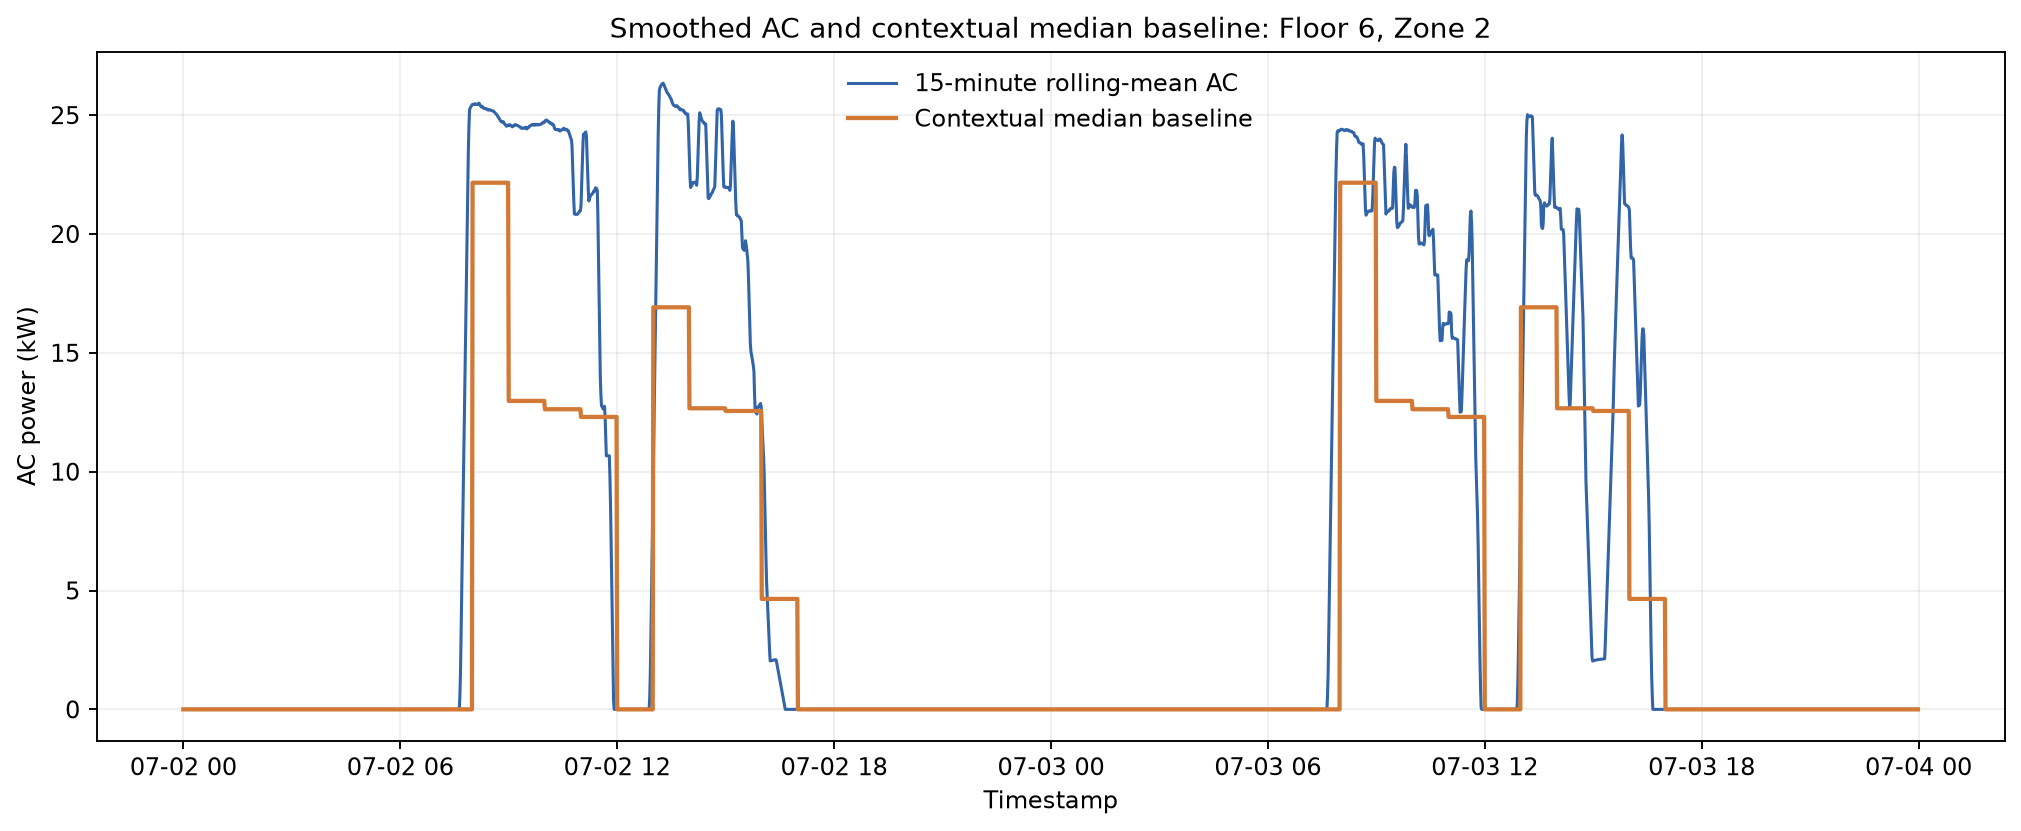

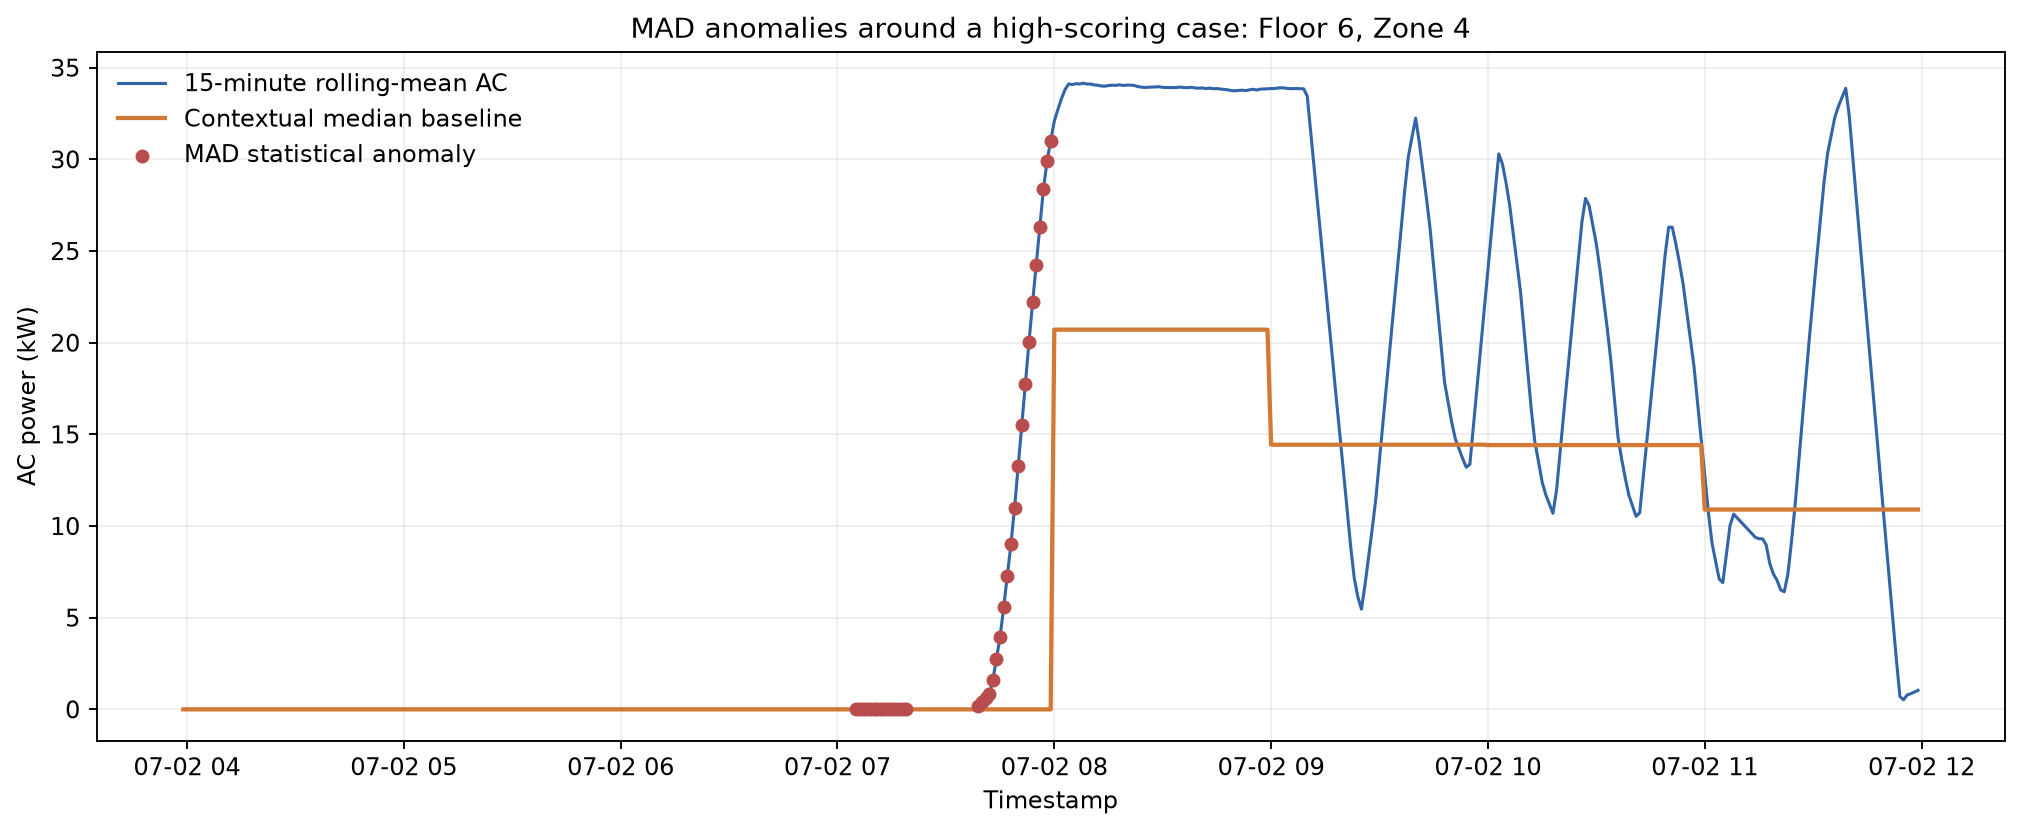

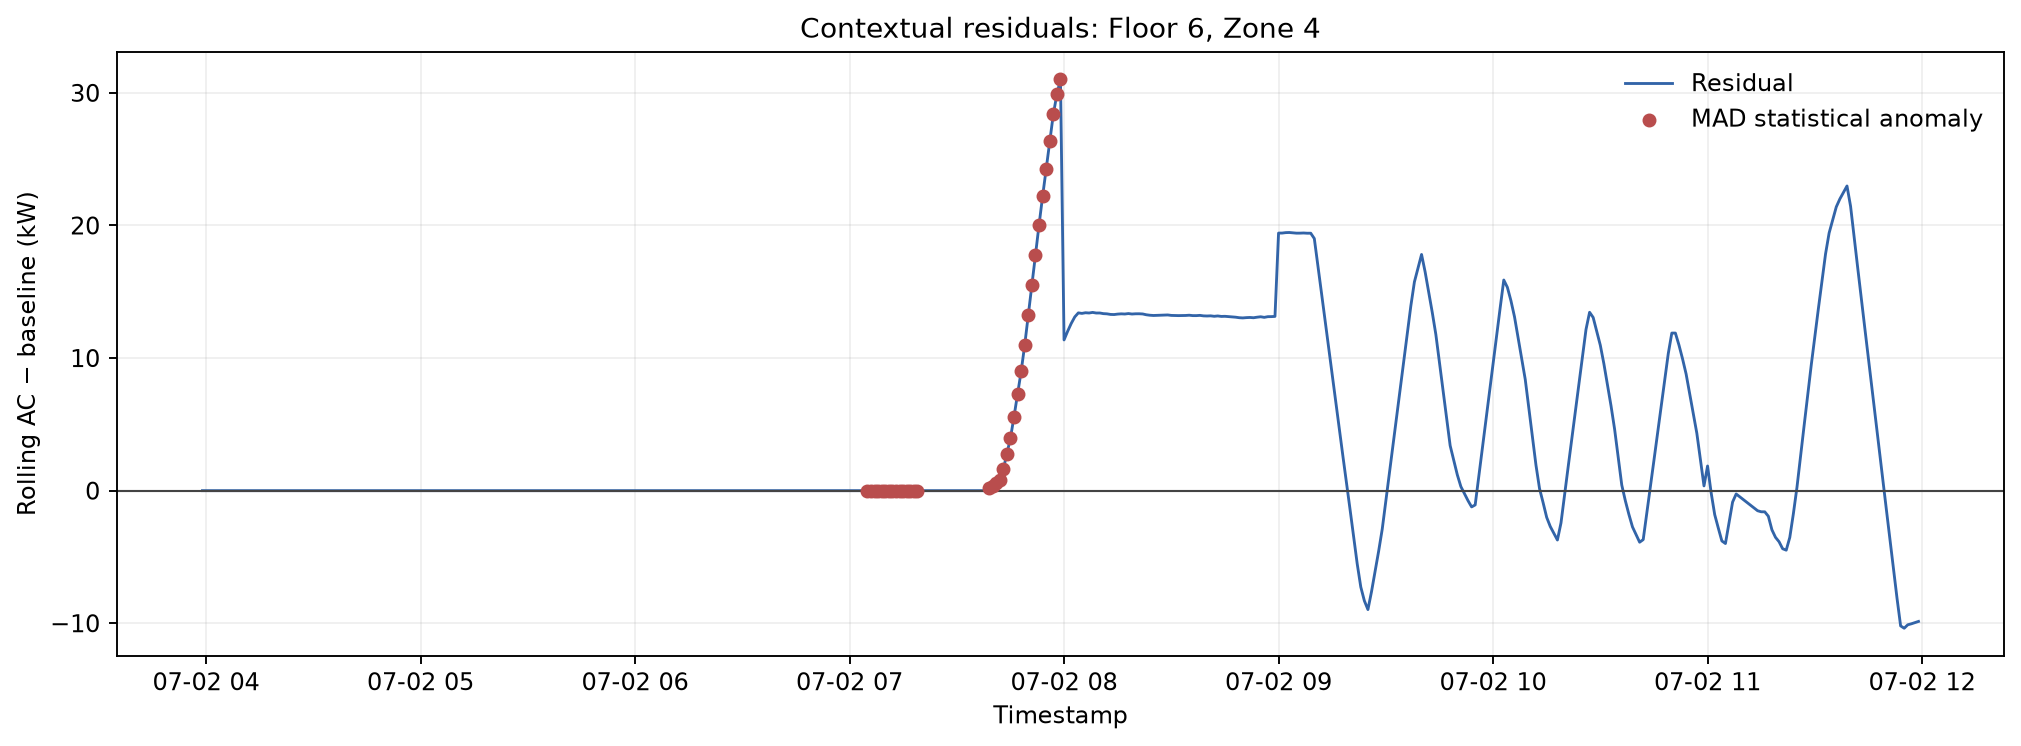

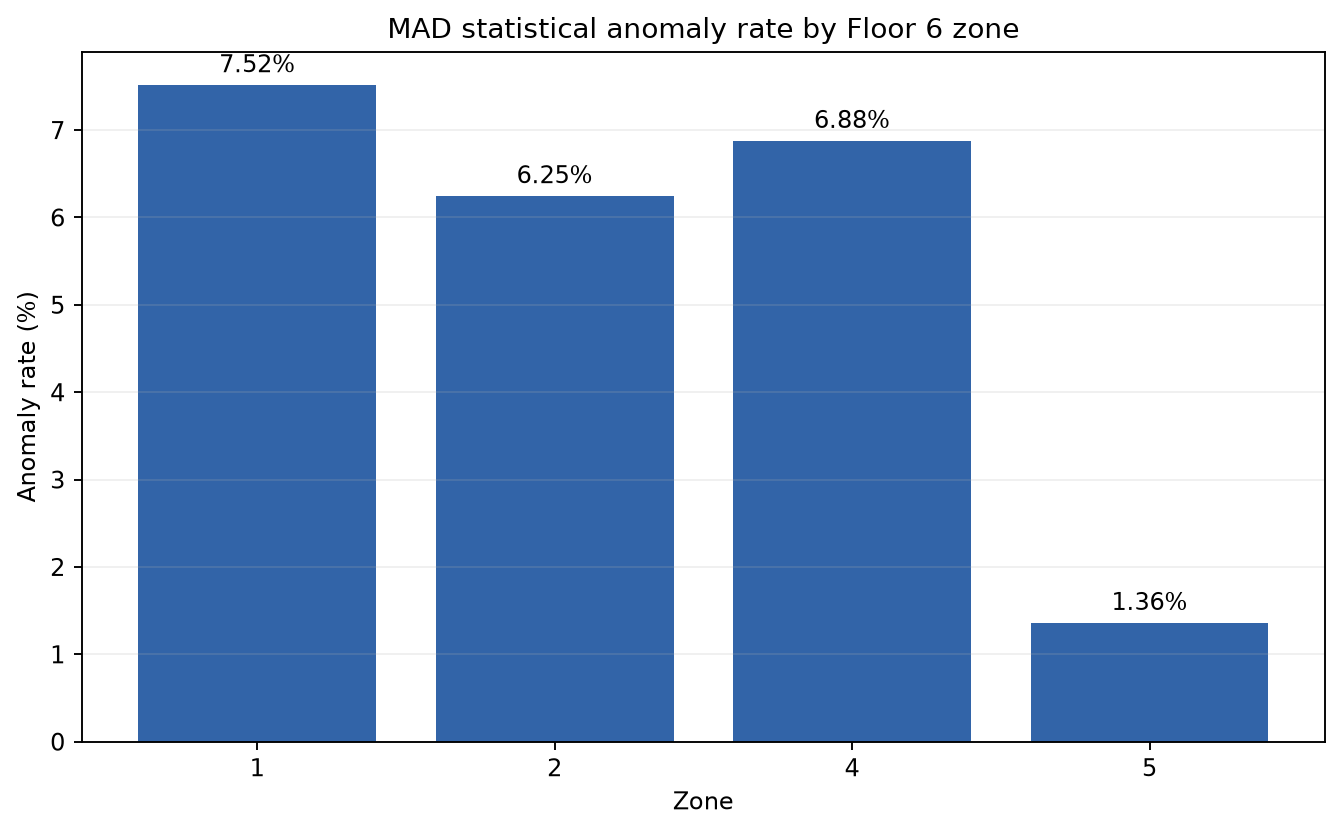

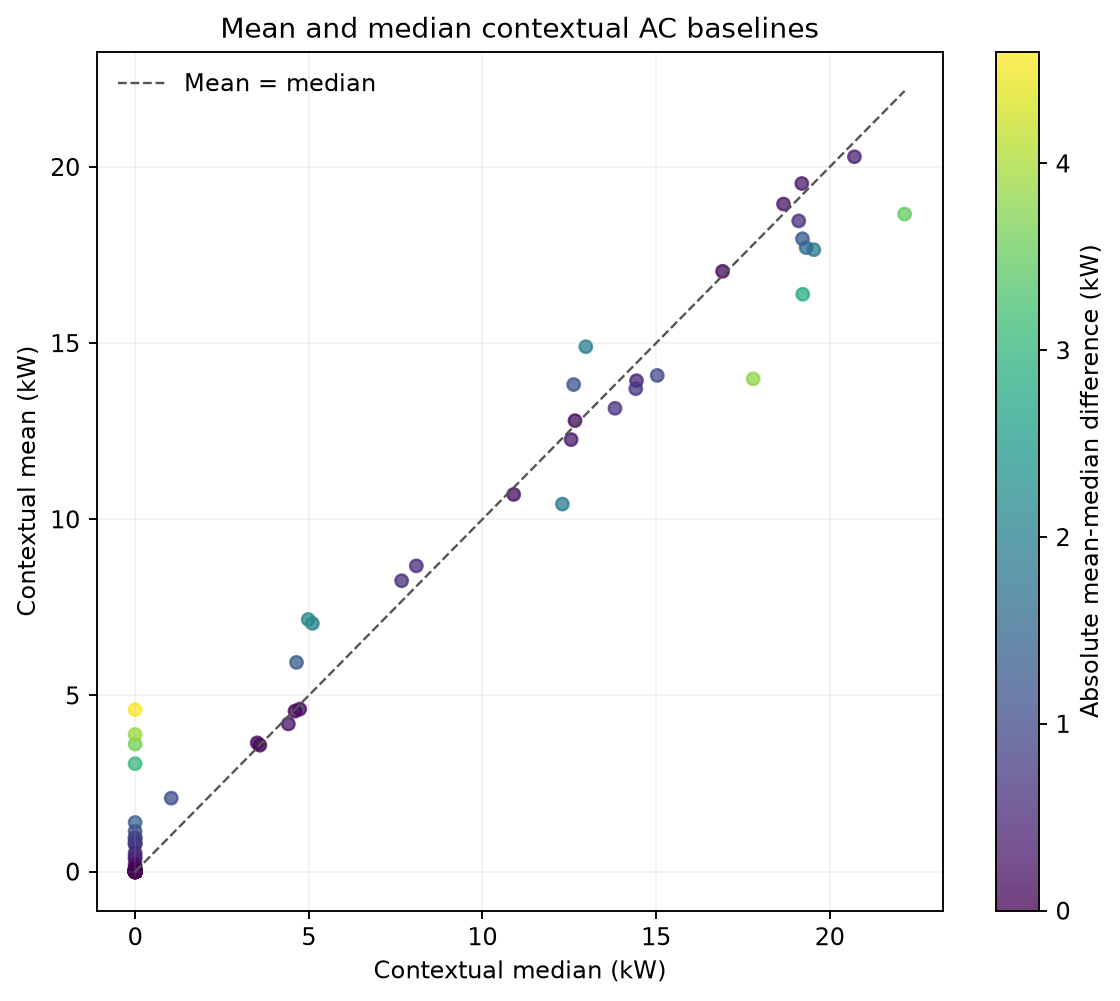

In [8]:
display(results['figure_index'])
for name in results['figure_index']['file_name'].iloc[:5]:
    display(Image(filename=str(FIGURE_DIR / name)))

## Week 5 visual explanation of MAD anomaly detection

The case study uses a new Floor 6 anomaly with a clear transition away from its expected contextual baseline. The upper panel compares the 15-minute rolling-mean AC signal with the median baseline; the lower panel shows the corresponding residual. The selected context has MAD=0, so the highlighted point is transparently identified by the empirical-resolution fallback rather than by division by zero.

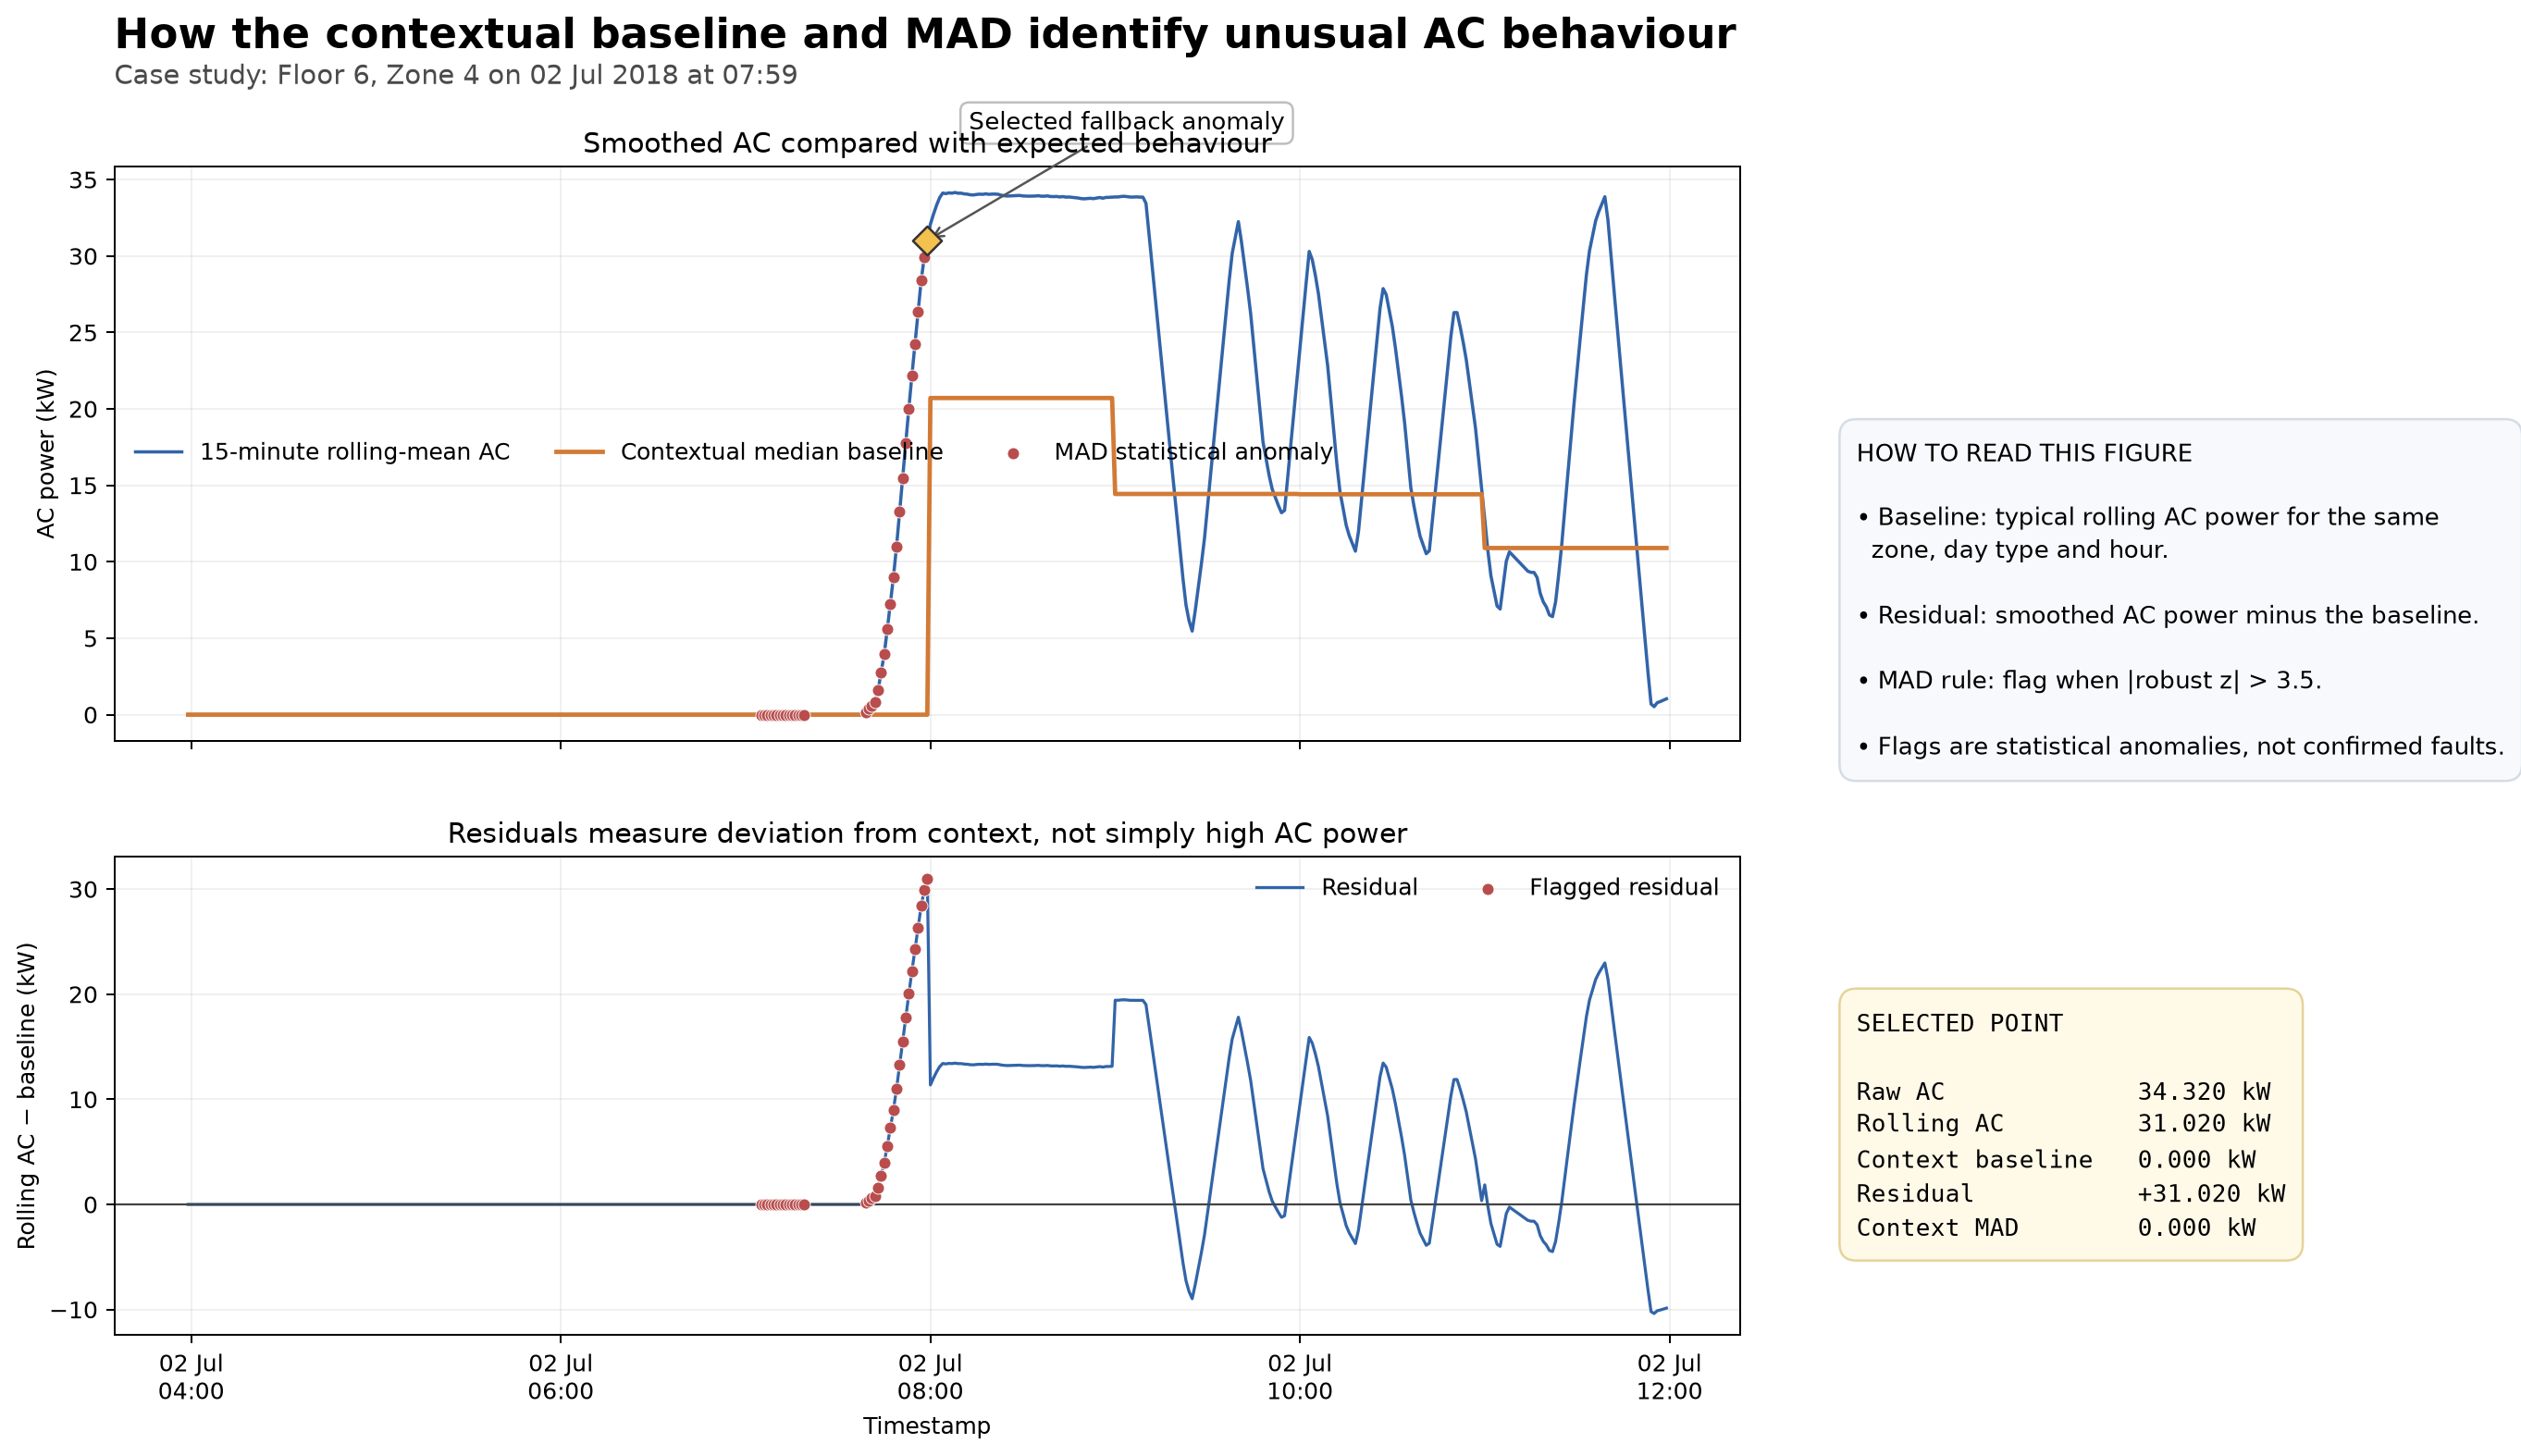

In [9]:
display(Image(filename=str(FIGURE_DIR / 'week5_06_mad_explanation_case_study.png')))

## Validation

The checks cover the Floor 6 scope, zones and date bounds, one-minute completeness, unique keys, target fields, baseline/MAD formulas, zero-MAD safety, threshold decisions, missing-target exclusion, zone-independent run segmentation, and manual spot checks.

In [10]:
display(results['manual_spot_checks'])
display(results['validation'])
assert results['validation']['passed'].all(), 'At least one Week 5 validation failed.'
print('All Week 5 validations passed.')

,timestamp,floor,zone,day_type,hour,total_AC_power_kw_rolling_mean_15min,baseline_median,residual,manual_residual,residual_median,contextual_mad,robust_z_score,manual_robust_z_score,residual_check_abs_error,robust_z_check_abs_error
0,2018-07-02 08:00:00,6,1,Weekday,8,27.670000,19.197000,8.473000,8.473000,0.0,0.671333,8.512967,8.512967,0.0,0.0
1,2018-08-06 11:25:00,6,1,Weekday,11,19.016667,17.796333,1.220333,1.220333,0.0,4.992667,0.164865,0.164865,0.0,0.0
2,2018-07-10 10:51:00,6,2,Weekday,10,6.891333,12.627333,-5.736000,-5.736000,0.0,1.895667,-2.040935,-2.040935,0.0,0.0
3,2018-08-14 15:16:00,6,2,Weekday,15,22.328667,12.554667,9.774000,9.774000,0.0,0.307333,21.450856,21.450856,0.0,0.0
4,2018-07-18 14:42:00,6,4,Weekday,14,13.674000,15.034667,-1.360667,-1.360667,0.0,5.010333,-0.183175,-0.183175,0.0,0.0
5,2018-08-23 14:07:00,6,4,Weekday,14,20.245333,15.034667,5.210667,5.210667,0.0,5.010333,0.701469,0.701469,0.0,0.0
6,2018-07-27 08:33:00,6,5,Weekday,8,0.000000,4.983333,-4.983333,-4.983333,0.0,3.954667,-0.849947,-0.849947,0.0,0.0
7,2018-08-31 16:59:00,6,5,Weekday,16,0.000000,1.040000,-1.040000,-1.040000,0.0,1.040000,-0.674500,-0.674500,0.0,0.0


,check,passed,detail
0,floor_is_exactly_6,True,floors=[6]
1,zones_are_exactly_1_2_4_5,True,"zones=[1, 2, 4, 5]"
2,zone_3_absent,True,Zone 3 rows=0
3,wrong_floors_absent,True,Floors 3/4/5/7 rows=0
4,analysis_period_matches_week4,True,2018-07-01 00:00:00 through 2018-09-01 23:59:00
5,one_minute_frequency_and_complete_zone_grids,True,"expected timestamps per zone=90,720"
6,timestamp_floor_zone_key_unique,True,duplicate keys=0
7,rolling_ac_target_exists,True,total_AC_power_kw_rolling_mean_15min
8,raw_ac_field_exists,True,total_AC_power_kw
9,baseline_counts_use_valid_targets_only,True,"baseline count sum=361,621; valid=361,621"


All Week 5 validations passed.


## Interpretation and limitations

The output identifies statistically unusual smoothed AC behaviour relative to each zone's weekday/weekend hourly pattern. It does not establish root cause or fault status. Calendar effects, holidays, occupancy, equipment state, and external temperature are outside this V1 context. Isolation Forest and other machine-learning methods remain future work; MAD pseudo-labels should not be treated as verified training ground truth.